# Moduł 2.5 - dwugałęziowa sieć CNN (EEG czasowe + PSD Welcha), LOSO

**Ważne różnice wobec pracy mgr, ze względu na definicje w module 1:**
- Oryginalnie klasyfikacja **T1 vs T0/T2**; tutaj klasyfikacja **T1 vs T2** 
- Oryginalny kod pracuje z **160 Hz, oknem [-1, +1] s, wybranymi runami i innym zestawem kanałów**, natomiast tutaj częstotliwość, długość epoki, kanały i runy przychodzą **bez zmian** z modułu 1 (zwykle 128 Hz, 1–3,5 s, 64 kanały, runy 3/4/7/8/11/12).
- stały próg 0,50 

0. Zależności i GPU
```bash
python -m pip install torch mne numpy pandas scikit-learn scipy matplotlib joblib ipykernel
```

In [ ]:
from pathlib import Path
import gc
import hashlib
import json
import os
import platform
import random
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score)
from mne.time_frequency import psd_array_welch
import mne
import sklearn

try:
    import torch
    from torch import nn
    from torch.nn import functional as nnF
    from torch.utils.data import Dataset, DataLoader
except ImportError as exc:
    raise ImportError("Brak PyTorch. Zainstaluj %pip install torch i zrestartuj kernel.") from exc

# ===== WSPÓLNE DANE Z MODUŁU 1 =====
DATA_BASE = Path.cwd() / "dane_eegmmidb"
MANIFEST_PATH = None  
RESULTS_BASE = Path.cwd() / "wyniki_modeli" / "EEG_PSD_DUAL_BRANCH"
VERIFY_FILE_HASHES = True

# ===== ARCHITEKTURA ORYGINALNEJ SIECI =====
F1 = 8
DEPTH_MULTIPLIER = 2
F2 = 16
RAW_TEMPORAL_KERNEL = 64
RAW_SEPARABLE_KERNEL = 16
PSD_TEMPORAL_KERNEL = 5
PSD_SEPARABLE_KERNEL = 7
DROPOUT = 0.5
DENSE_UNITS = 64

# ===== WELCH + LOG-PSD (jak w źródłowym kodzie) =====
PSD_FMIN, PSD_FMAX = 8.0, 30.0
PSD_DESIRED_NFFT = 256
PSD_OVERLAP_FRAC = 0.5
PSD_LOG_EPS = 1e-12  # jednostki V**2 / Hz
PSD_CACHE_BATCH = 128

# ===== TRENING: te same FOLDY LOSO co inne modele =====
SEED = 42
MAX_EPOCHS = 300
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
ADAM_BETAS = (0.9, 0.999)
ADAM_EPS = 1e-7
BN_EPS = 1e-3
BN_MOMENTUM = 0.01
FOCAL_GAMMA, FOCAL_ALPHA = 2.0, 0.75
USE_CLASS_WEIGHTS = True
REFIT_ON_ALL_NON_TEST = False
AUGMENT_TRAIN = True
AUGMENT_FRACTION = 0.5
AUGMENT_LABEL = 2
AUGMENT_NOISE_STD_FRACTION = 0.05
AUGMENT_TIME_SHIFT = 20
AUGMENT_AMP_RANGE = (0.9, 1.1)

# ===== WERYFIKOWALNOŚĆ =====
REQUIRE_GPU = True
TUNE_THRESHOLD = False
DEFAULT_THRESHOLD = 0.50
MIN_VALIDATION_RECALL = 0.20
SAVE_MODELS = True
SAVE_PLOTS = True
SHOW_PLOTS = True
TEST_SUBJECT_TO_SHOW = None
N_SAMPLES = 10
MAX_FOLDS = None         # None = pełne LOSO
OVERWRITE_EXISTING = False

assert F1 == 8 and DEPTH_MULTIPLIER == 2 and F2 == 16 and DENSE_UNITS == 64
assert 0 < DROPOUT < 1 and MAX_EPOCHS > 0 and BATCH_SIZE >= 2
assert 0 <= AUGMENT_FRACTION <= 1 and 0 < DEFAULT_THRESHOLD < 1
assert AUGMENT_LABEL in (1, 2) and AUGMENT_TIME_SHIFT > 0
assert MAX_FOLDS is None or MAX_FOLDS >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| urządzenie:", DEVICE,
      "| GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "brak")
if REQUIRE_GPU and DEVICE.type != "cuda":
    raise RuntimeError(
        "PyTorch nie wykrywa GPU CUDA. Sprawdź sterownik NVIDIA, zainstaluj wersję "
        "PyTorch z CUDA albo ustaw REQUIRE_GPU=False do próby na CPU."
    )


PyTorch: 2.9.0+cu128 | urządzenie: cuda | GPU: NVIDIA GeForce RTX 5090


## 1. Wczytanie kanonicznego zestawu danych i podziałów LOSO

In [2]:
def read_json(path):
    with Path(path).open(encoding="utf-8") as f:
        return json.load(f)


def sha256_file(path, block_size=1024 * 1024):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(block_size), b""):
            h.update(block)
    return h.hexdigest()


def stable_hash(obj, length=12):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False)
                          .encode("utf-8")).hexdigest()[:length]


if MANIFEST_PATH is None:
    pointer = read_json(DATA_BASE / "ostatni_zestaw.json")
    manifest_path = (DATA_BASE / pointer["manifest_relative_path"]).resolve()
else:
    manifest_path = Path(MANIFEST_PATH).expanduser().resolve()
manifest = read_json(manifest_path)
if manifest.get("schema_version") != "1.0":
    raise ValueError("Wymagany format manifestu danych modułu 1: schema_version=1.0.")
dataset_dir = manifest_path.parent
for key, fileinfo in manifest["files"].items():
    filename = dataset_dir / fileinfo["path"]
    if not filename.is_file():
        raise FileNotFoundError(filename)
    if VERIFY_FILE_HASHES and sha256_file(filename) != fileinfo["sha256"]:
        raise ValueError(f"Zmieniono plik {key} od czasu przygotowania danych: {filename}")

X_all = np.load(dataset_dir / manifest["files"]["X"]["path"], mmap_mode="r")
y_all = np.load(dataset_dir / manifest["files"]["y"]["path"], mmap_mode="r")
groups = np.load(dataset_dir / manifest["files"]["groups"]["path"], mmap_mode="r")
run_all = np.load(dataset_dir / manifest["files"]["runs"]["path"], mmap_mode="r")
splits = read_json(dataset_dir / manifest["files"]["splits"]["path"])
SUBJECT_IDS = list(map(int, manifest["subject_ids"]))
CLASS_NAMES = {int(k): v for k, v in manifest["labels"].items()}
SFREQ = float(manifest["preprocessing"]["target_sfreq"])
N_CHANNELS, N_TIMES = map(int, X_all.shape[1:])

if (X_all.ndim != 3 or X_all.dtype != np.float32 or
        list(X_all.shape) != manifest["X_shape"]):
    raise ValueError("X: oczekiwano float32 [epoki, kanały, czas] z modułu 1.")
if not (len(X_all) == len(y_all) == len(groups) == len(run_all)):
    raise ValueError("Niezgodne liczby epok w X/y/groups/runs.")
if y_all.dtype != np.int8 or groups.dtype != np.int16 or run_all.dtype != np.int8:
    raise ValueError("Niezgodne typy danych.")
if (set(np.unique(y_all).tolist()) != {1, 2} or
        np.unique(groups).tolist() != SUBJECT_IDS or
        manifest["signal_unit"] != "V" or int(manifest["positive_label"]) != 2):
    raise ValueError("Wymagane etykiety 1=T1 i 2=T2 oraz sygnał w V.")
if splits["dataset_id"] != manifest["dataset_id"]:
    raise ValueError("Zapisane podziały LOSO nie pasują do danych.")
if [int(f["test_subject"]) for f in splits["folds"]] != SUBJECT_IDS:
    raise ValueError("Brak któregoś uczestnika w podziałach LOSO.")
for fold in splits["folds"]:
    training = set(map(int, fold["train_subjects_internal"]))
    validation = set(map(int, fold["validation_subjects"]))
    test = set(map(int, fold["test_subjects"]))
    if (training & validation or training & test or validation & test or
            training | validation | test != set(SUBJECT_IDS) or
            test != {int(fold["test_subject"])}):
        raise ValueError(f"Niewłaściwe podziały uczestników dla folda {fold['fold']}")
if N_CHANNELS < 2 or N_TIMES < 64:
    raise ValueError("Niewystarczająca liczba kanałów lub próbek dla oryginalnej sieci.")
if not (0 < PSD_FMIN < PSD_FMAX <= SFREQ / 2):
    raise ValueError("Pasmo PSD musi mieścić się w zakresie Nyquista.")

SELECTED_FOLDS = splits["folds"][:MAX_FOLDS] if MAX_FOLDS is not None else splits["folds"]
IS_FULL_LOSO = len(SELECTED_FOLDS) == len(SUBJECT_IDS)
print("Dane:", manifest["dataset_id"], "| X:", X_all.shape, "| sfreq:", SFREQ)
print("Klasy:", CLASS_NAMES, "| zadania:", manifest["task_types"])
print("Wybrane foldy:", len(SELECTED_FOLDS), "| pełne LOSO:", IS_FULL_LOSO)
if "motor_execution" in manifest["task_types"]:
    warnings.warn("Zbiór zawiera również rzeczywiste wykonywanie ruchu, nie tylko motor imagery.")

Dane: 0a8da1dbe454 | X: (9844, 64, 321) | sfreq: 128.0
Klasy: {1: 'lewa dłoń', 2: 'prawa dłoń'} | zadania: ['motor_execution', 'motor_imagery']
Wybrane foldy: 109 | pełne LOSO: True


/tmp/ipykernel_367723/4141383495.py:79: UserWarning: Zbiór zawiera również rzeczywiste wykonywanie ruchu, nie tylko motor imagery.
  warnings.warn("Zbiór zawiera również rzeczywiste wykonywanie ruchu, nie tylko motor imagery.")


## 2. PSD metodą Welcha — wspólna, deterministyczna cecha wszystkich foldów

Obliczamy **log10(PSD + 1e-12)** dla każdej epoki, każdego kanału i częstotliwości z zakresu **8–30 Hz**, metodą Welcha z **oknem Hann** i **50% nakładaniem** (jak w załączonym kodzie). Wynik zapisujemy raz jako tablicę `.npy` na dysku, żeby 109 foldów nie liczyło PSD ponownie. Samo PSD **nie dopasowuje żadnych parametrów do etykiet**, dlatego wspólny cache nie powoduje przecieku. **Standaryzacja PSD** jest natomiast uczona na uczestnikach treningowych **oddzielnie dla każdego folda**.

Przy domyślnych ustawieniach modułu 1 sygnał jest już przefiltrowany do 8–30 Hz. Ten notebook nie zmienia danych oryginalnego zbioru. Parametry Welcha są równe Keras w próbkach (256/128), jednak przy 128 Hz zamiast 160 Hz okno trwa 2 s zamiast 1,6 s, a siatka ma 45 zamiast 36 punktów. Wymiar wejścia PSD i liczba parametrów Dense są dlatego zależne od modułu 1.

In [3]:
N_FFT = min(int(PSD_DESIRED_NFFT), N_TIMES)
N_OVERLAP = int(N_FFT * PSD_OVERLAP_FRAC)
PSD_CONFIG = {"dataset_id": manifest["dataset_id"], "sfreq": SFREQ,
              "fmin": PSD_FMIN, "fmax": PSD_FMAX, "n_fft": N_FFT,
              "n_per_seg": N_FFT, "n_overlap": N_OVERLAP,
              "window": "hann", "average": "mean", "log_eps": PSD_LOG_EPS}
PSD_CACHE_ID = stable_hash(PSD_CONFIG)
PSD_CACHE_DIR = RESULTS_BASE / "cache_psd"
PSD_CACHE_DIR.mkdir(parents=True, exist_ok=True)
PSD_PATH = PSD_CACHE_DIR / f"{manifest['dataset_id']}_{PSD_CACHE_ID}.npy"
PSD_META_PATH = PSD_PATH.with_suffix(".json")


def psd_welch_log(data):
    result, freqs = psd_array_welch(
        np.asarray(data, dtype=np.float32), sfreq=SFREQ,
        fmin=PSD_FMIN, fmax=PSD_FMAX,
        n_fft=N_FFT, n_per_seg=N_FFT, n_overlap=N_OVERLAP,
        window="hann", average="mean", n_jobs=1, verbose="ERROR")
    return np.log10(np.maximum(result, 0.0) + PSD_LOG_EPS).astype(np.float32), freqs


if PSD_PATH.is_file() and PSD_META_PATH.is_file():
    psd_meta = read_json(PSD_META_PATH)
    if psd_meta["config"] != PSD_CONFIG:
        raise ValueError("Nieprawidłowe metadane cache PSD.")
    PSD_all = np.load(PSD_PATH, mmap_mode="r")
    FREQS = np.asarray(psd_meta["frequencies_hz"], dtype=float)
    if (PSD_all.shape != (len(X_all), N_CHANNELS, len(FREQS)) or
            PSD_all.dtype != np.float32):
        raise ValueError("Cache PSD ma niepoprawny kształt lub dtype.")
    print("Wczytano cache PSD:", PSD_PATH)
elif PSD_PATH.exists() or PSD_META_PATH.exists():
    raise RuntimeError("Niekompletny cache PSD: usuń plik .npy i .json o tej samej nazwie, a potem uruchom ponownie.")
else:
    sample_psd, FREQS = psd_welch_log(X_all[:1])
    N_FREQS = len(FREQS)
    psd_arr = np.lib.format.open_memmap(
        PSD_PATH, mode="w+", dtype=np.float32,
        shape=(len(X_all), N_CHANNELS, N_FREQS))
    for start in range(0, len(X_all), PSD_CACHE_BATCH):
        stop = min(start + PSD_CACHE_BATCH, len(X_all))
        psd_part, freq_part = psd_welch_log(X_all[start:stop])
        if not np.array_equal(freq_part, FREQS):
            raise ValueError("Niespójna siatka częstotliwości PSD.")
        psd_arr[start:stop] = psd_part
        if start == 0 or stop == len(X_all) or stop % (PSD_CACHE_BATCH * 20) == 0:
            print("PSD:", stop, "/", len(X_all))
    psd_arr.flush()
    del psd_arr
    with PSD_META_PATH.open("w", encoding="utf-8") as f:
        json.dump({"config": PSD_CONFIG, "frequencies_hz": FREQS.tolist()}, f, indent=2)
    PSD_all = np.load(PSD_PATH, mmap_mode="r")
N_FREQS = PSD_all.shape[-1]
if N_FREQS < 4:
    raise ValueError("Za mało punktów częstotliwości PSD dla poolingu 1×2 + 1×2.")
print("PSD:", PSD_all.shape, "| f(Hz):", FREQS[0], "..", FREQS[-1])

Wczytano cache PSD: /home/wsl/phd/01_przygotowanie_danych_EEGMMIDB/wyniki_modeli/EEG_PSD_DUAL_BRANCH/cache_psd/0a8da1dbe454_e1f4308e9983.npy
PSD: (9844, 64, 45) | f(Hz): 8.0 .. 30.0


## 3. Standaryzacja i podawanie danych partiami

Jak w oryginalnym kodzie, osobno dla obu torów uczymy `StandardScaler` na spłaszczonej macierzy `[kanał × czas]` i `[kanał × częstotliwość]`, a następnie przywracamy wymiary wejściowe CNN. **Każdy scaler jest dopasowywany tylko do indeksów treningowych**; zastosowanie `partial_fit` zmniejsza zapotrzebowanie na RAM. Augmentowane kopie generujemy deterministycznie raz w sensie logicznym (te same kopie w każdej epoce), tylko dla treningu, przed dopasowaniem skalerów i wag klas. PSD kopii liczone jest po augmentacji. Szum wynosi 5% odchylenia standardowego kanału danej epoki, nie 0,05 V. Stałe kopie augmentowane (RAW i PSD) są buforowane w RAM tylko na czas danego folda. Obie reprezentacje są ładowane partiami, a nie kopiowane w całości do pamięci GPU.

In [4]:
def select_augmented_indices(train_idx, seed):
    """Jednorazowy wybór kopii: Bernoulli(p=0.5) dla klasy pozytywnej."""
    ids = np.asarray(train_idx, dtype=np.int64)
    if not AUGMENT_TRAIN:
        return np.empty(0, dtype=np.int64)
    candidates = ids[np.asarray(y_all[ids]) == AUGMENT_LABEL]
    rng = np.random.default_rng(seed)
    return candidates[rng.random(len(candidates)) < AUGMENT_FRACTION]


def augmented_raw_values(ids, seed):
    """Identyczna kopia dla danego indeksu i folda, niezależnie od batcha/epoki."""
    raw = np.array(X_all[ids], dtype=np.float32, copy=True)
    for row, idx in enumerate(ids):
        rng = np.random.default_rng(np.random.SeedSequence([int(seed), int(idx), 1]))
        ch_std = raw[row].std(axis=-1, keepdims=True)
        raw[row] += rng.normal(0, AUGMENT_NOISE_STD_FRACTION * ch_std,
                               size=raw[row].shape).astype(np.float32)
        raw[row] = np.roll(raw[row], int(rng.integers(-AUGMENT_TIME_SHIFT,
                                                    AUGMENT_TIME_SHIFT)), axis=1)
        raw[row] *= rng.uniform(*AUGMENT_AMP_RANGE)
    return raw


def fit_input_scalers(train_idx, aug_idx=None, seed=SEED, chunk=256):
    raw_scaler = StandardScaler()
    psd_scaler = StandardScaler()
    for start in range(0, len(train_idx), chunk):
        ids = train_idx[start:start+chunk]
        raw = np.asarray(X_all[ids], dtype=np.float32).reshape(len(ids), -1)
        psd = np.asarray(PSD_all[ids], dtype=np.float32).reshape(len(ids), -1)
        raw_scaler.partial_fit(raw)
        psd_scaler.partial_fit(psd)
    if aug_idx is not None:
        for start in range(0, len(aug_idx), chunk):
            ids = aug_idx[start:start+chunk]
            raw = augmented_raw_values(ids, seed)
            psd, _ = psd_welch_log(raw)
            raw_scaler.partial_fit(raw.reshape(len(ids), -1))
            psd_scaler.partial_fit(psd.reshape(len(ids), -1))
    return raw_scaler, psd_scaler


def to_inputs(raw_values, psd_values, raw_scaler, psd_scaler):
    """Zwraca NCHW, zgodne z torch.nn.Conv2d: [N, 1, kanały, próbki]."""
    n = len(raw_values)
    raw_scaled = raw_scaler.transform(
        np.asarray(raw_values, dtype=np.float32).reshape(n, -1)
    ).astype(np.float32).reshape(n, 1, N_CHANNELS, N_TIMES)
    psd_scaled = psd_scaler.transform(
        np.asarray(psd_values, dtype=np.float32).reshape(n, -1)
    ).astype(np.float32).reshape(n, 1, N_CHANNELS, N_FREQS)
    return torch.from_numpy(raw_scaled), torch.from_numpy(psd_scaled)


class EEGPSDDataset(Dataset):
    """Indeksy epok; w collate_fn czyta i skaluje całe partie, bez kopiowania całego zbioru."""
    def __init__(self, epoch_indices, raw_scaler, psd_scaler,
                 training, seed, class_weights=None, aug_idx=None):
        self.raw_scaler, self.psd_scaler = raw_scaler, psd_scaler
        self.training = bool(training)
        self.class_weights = class_weights
        self.seed = int(seed)
        self.epoch = 0
        self.batch_no = 0
        self.ids = np.asarray(epoch_indices, dtype=np.int64)
        self.is_augmented = np.zeros(len(self.ids), dtype=bool)
        self.n_original = len(self.ids)
        self.aug_raw = self.aug_psd = None
        if aug_idx is not None and training:
            chosen = np.asarray(aug_idx, dtype=np.int64)
            if not np.isin(chosen, self.ids).all():
                raise ValueError("Augmentacja może dotyczyć tylko zbioru treningowego.")
            self.ids = np.concatenate([self.ids, chosen])
            self.is_augmented = np.r_[self.is_augmented, np.ones(len(chosen), dtype=bool)]
            # Stałe kopie w RAM tylko dla bieżącego folda; bez liczenia PSD 300 razy.
            self.aug_raw = np.empty((len(chosen), N_CHANNELS, N_TIMES), dtype=np.float32)
            self.aug_psd = np.empty((len(chosen), N_CHANNELS, N_FREQS), dtype=np.float32)
            for start in range(0, len(chosen), PSD_CACHE_BATCH):
                end = min(start + PSD_CACHE_BATCH, len(chosen))
                raw = augmented_raw_values(chosen[start:end], self.seed)
                self.aug_raw[start:end] = raw
                self.aug_psd[start:end], _ = psd_welch_log(raw)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, position):
        # Dane pobieramy wspólnie w collate_batch, zamiast osobno dla każdej epoki.
        return int(position)

    def set_epoch(self, epoch):
        self.epoch = int(epoch)
        self.batch_no = 0

    def collate_batch(self, positions):
        positions = np.asarray(positions, dtype=np.int64)
        idx = self.ids[positions]
        raw = np.array(X_all[idx], dtype=np.float32, copy=True)
        psd = np.array(PSD_all[idx], dtype=np.float32, copy=True)
        augmented = self.is_augmented[positions]
        if augmented.any():
            aug_pos = positions[augmented] - self.n_original
            raw[augmented] = self.aug_raw[aug_pos]
            psd[augmented] = self.aug_psd[aug_pos]
        self.batch_no += 1
        raw_tensor, psd_tensor = to_inputs(raw, psd, self.raw_scaler, self.psd_scaler)
        labels = (np.asarray(y_all[idx]) == 2).astype(np.float32)
        if self.training and self.class_weights is not None:
            weights = np.where(labels == 1, self.class_weights[1],
                               self.class_weights[0]).astype(np.float32)
        else:
            weights = np.ones(len(idx), dtype=np.float32)
        return (raw_tensor, psd_tensor, torch.from_numpy(labels), torch.from_numpy(weights))


def predict_probability_T2(model, idx, raw_scaler, psd_scaler, batch_size=None):
    dataset = EEGPSDDataset(idx, raw_scaler, psd_scaler, training=False, seed=SEED)
    loader = DataLoader(dataset, batch_size=batch_size or BATCH_SIZE,
                        shuffle=False, num_workers=0, collate_fn=dataset.collate_batch,
                        pin_memory=(DEVICE.type == "cuda"))
    model.eval()
    parts = []
    with torch.inference_mode():
        for raw, psd, _, _ in loader:
            prob = model(raw.to(DEVICE, non_blocking=True),
                         psd.to(DEVICE, non_blocking=True))
            parts.append(prob.cpu().numpy().reshape(-1))
    return np.concatenate(parts).astype(np.float32) if parts else np.array([], dtype=np.float32)


## 4. Architektura z pracy mgr — PyTorch (`nn.Module`), zgodny układ warstw, filtrów i inicjalizacji Keras


In [5]:
def binary_focal_loss(y_true, y_pred, sample_weight=None):
    """Focal loss (gamma=2, alpha=0,75 dla T2), ważenie per próbka przed redukcją (celowa korekta źródła Keras)."""
    y = y_true.reshape(-1).float()
    p = y_pred.reshape(-1).clamp(min=1e-7, max=1. - 1e-7)
    bce = nnF.binary_cross_entropy(p, y, reduction="none")
    p_t = torch.where(y > 0.5, p, 1. - p)
    alpha_t = y * FOCAL_ALPHA + (1. - y) * (1. - FOCAL_ALPHA)
    loss = alpha_t * (1. - p_t).pow(FOCAL_GAMMA) * bce
    if sample_weight is not None:
        loss = loss * sample_weight.reshape(-1)
    return loss.mean()


def same_temporal_conv(in_channels, out_channels, kernel_width, groups=1):
    """Keras padding='same', w tym asymetryczny padding dla parzystego jądra."""
    left = (kernel_width - 1) // 2
    right = (kernel_width - 1) - left
    return nn.Sequential(
        nn.ZeroPad2d((left, right, 0, 0)),
        nn.Conv2d(in_channels, out_channels, (1, kernel_width),
                  groups=groups, bias=False),
    )


class EEGPSDBranch(nn.Module):
    def __init__(self, n_channels, temporal_kernel, separable_kernel, pool_1, pool_2):
        super().__init__()
        spatial_filters = F1 * DEPTH_MULTIPLIER
        self.temporal = same_temporal_conv(1, F1, temporal_kernel)
        # TensorFlow: BatchNorm momentum=0.99, eps=1e-3.
        # PyTorch stosuje momentum=1-0.99=0.01 dla średniej kroczącej.
        self.bn1 = nn.BatchNorm2d(F1, eps=BN_EPS, momentum=BN_MOMENTUM)
        self.spatial = nn.Conv2d(F1, spatial_filters, (n_channels, 1),
                                 groups=F1, bias=False)
        self.bn2 = nn.BatchNorm2d(spatial_filters, eps=BN_EPS, momentum=BN_MOMENTUM)
        self.pool1 = nn.AvgPool2d((1, pool_1))
        self.drop1 = nn.Dropout(DROPOUT)
        self.sep_depthwise = same_temporal_conv(
            spatial_filters, spatial_filters, separable_kernel, groups=spatial_filters)
        self.sep_pointwise = nn.Conv2d(spatial_filters, F2, (1, 1), bias=False)
        self.bn3 = nn.BatchNorm2d(F2, eps=BN_EPS, momentum=BN_MOMENTUM)
        self.pool2 = nn.AvgPool2d((1, pool_2))
        self.drop2 = nn.Dropout(DROPOUT)

    def forward(self, x):
        x = self.bn1(self.temporal(x))
        x = self.drop1(self.pool1(nnF.elu(self.bn2(self.spatial(x)))))
        x = self.sep_pointwise(self.sep_depthwise(x))
        x = self.drop2(self.pool2(nnF.elu(self.bn3(x))))
        return torch.flatten(x.permute(0, 2, 3, 1).contiguous(), start_dim=1)  # jak Keras NHWC


class DualBranchEEGPSD(nn.Module):
    def __init__(self, n_channels, n_times, n_freqs):
        super().__init__()
        if n_times < 32 or n_freqs < 4:
            raise ValueError("Za mało próbek czasu lub częstotliwości dla poolingu.")
        self.raw_branch = EEGPSDBranch(n_channels, RAW_TEMPORAL_KERNEL,
                                        RAW_SEPARABLE_KERNEL, 4, 8)
        self.psd_branch = EEGPSDBranch(n_channels, PSD_TEMPORAL_KERNEL,
                                        PSD_SEPARABLE_KERNEL, 2, 2)
        flattened_dim = F2 * (n_times // 32 + n_freqs // 4)
        self.dense = nn.Linear(flattened_dim, DENSE_UNITS)
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(DENSE_UNITS, 1)

    def forward(self, raw, psd):
        x = torch.cat((self.raw_branch(raw), self.psd_branch(psd)), dim=1)
        x = self.dropout(nnF.elu(self.dense(x)))
        return torch.sigmoid(self.classifier(x))


def initialize_keras_glorot(module):
    """Glorot uniform z fan_in/fan_out obliczonymi jak dla jąder Keras.
    Głębokościowe jądro Keras: [kh, kw, in_channels, depth_multiplier].
    """
    if isinstance(module, nn.Conv2d):
        if module.groups == module.in_channels and module.groups > 1:
            kh, kw = module.kernel_size
            fan_in = kh * kw * module.in_channels
            fan_out = kh * kw * (module.out_channels // module.in_channels)
            bound = (6.0 / (fan_in + fan_out)) ** 0.5
            nn.init.uniform_(module.weight, -bound, bound)
        else:
            nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)
        module.reset_running_stats()


def build_master_eeg_psd_network(n_channels=N_CHANNELS, n_times=N_TIMES, n_freqs=N_FREQS):
    model = DualBranchEEGPSD(n_channels, n_times, n_freqs)
    model.apply(initialize_keras_glorot)
    return model


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


seed_everything(SEED)
DEMO_MODEL = build_master_eeg_psd_network()
print(DEMO_MODEL)
print("Wejście RAW:", (None, 1, N_CHANNELS, N_TIMES),
      "| PSD:", (None, 1, N_CHANNELS, N_FREQS))
print("Parametry sieci:", sum(p.numel() for p in DEMO_MODEL.parameters()))
# Kontrola wymiarów dla oryginału Keras (64 kanały, 321 próbek, 36 częstotliwości).
_reference = build_master_eeg_psd_network(64, 321, 36)
assert sum(p.numel() for p in _reference.parameters()) == 23225
assert _reference.dense.in_features == 304
with torch.inference_mode():
    assert DEMO_MODEL.eval()(torch.zeros(1, 1, N_CHANNELS, N_TIMES),
                             torch.zeros(1, 1, N_CHANNELS, N_FREQS)).shape == (1, 1)
print("Kontrola architektury Keras: 23 225 parametrów dla wejść 64×321 i 64×36 — OK")
del DEMO_MODEL, _reference


DualBranchEEGPSD(
  (raw_branch): EEGPSDBranch(
    (temporal): Sequential(
      (0): ZeroPad2d((31, 32, 0, 0))
      (1): Conv2d(1, 8, kernel_size=(1, 64), stride=(1, 1), bias=False)
    )
    (bn1): BatchNorm2d(8, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
    (spatial): Conv2d(8, 16, kernel_size=(64, 1), stride=(1, 1), groups=8, bias=False)
    (bn2): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
    (pool1): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (drop1): Dropout(p=0.5, inplace=False)
    (sep_depthwise): Sequential(
      (0): ZeroPad2d((7, 8, 0, 0))
      (1): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), groups=16, bias=False)
    )
    (sep_pointwise): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
    (pool2): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (drop2): Dropout(p=0

## 5. Trening przez 300 epok, walidacja, zapis i metryki

Uczymy sieć na `train_subjects_internal` przez dokładnie `MAX_EPOCHS=300`, obserwując `validation_subjects`. Jak w Keras nie stosujemy early stoppingu ani przywracania najlepszych wag: model z ostatniej epoki jest modelem końcowym. Domyślnie nie ma ponownego treningu (refitu). Zachowujemy podział LOSO po osobach, żeby zapobiegać przeciekom. W razie jawnego włączenia refitu jest on również wykonywany przez 300 epok. Domyślny próg 0,5 nie jest dobierany na teście. Pole `best_epoch` w CSV jest zachowane dla zgodności z modułem 3, ale oznacza wybraną ostatnią epokę; rzeczywiste minimum val_loss zapisuje się osobno.

In [6]:
def balanced_weights(train_idx):
    if not USE_CLASS_WEIGHTS:
        return None
    y_train = (np.asarray(y_all[train_idx]) == 2).astype(np.int8)
    weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
    return {0: float(weights[0]), 1: float(weights[1])}


def make_loader(idx, raw_scaler, psd_scaler, training, seed, aug_idx=None):
    dataset = EEGPSDDataset(
        idx, raw_scaler, psd_scaler, training, seed,
        class_weights=balanced_weights(np.concatenate([idx, aug_idx]) if aug_idx is not None else idx) if training else None,
        aug_idx=aug_idx if training else None)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=training,
                      num_workers=0, collate_fn=dataset.collate_batch,
                      pin_memory=(DEVICE.type == "cuda"),
                      generator=torch.Generator().manual_seed(seed))


def run_epoch(model, loader, optimizer=None, epoch=1):
    """Trening lub ewaluacja po jednej epoce, z metrykami dla całego zbioru."""
    training = optimizer is not None
    model.train(training)
    loader.dataset.set_epoch(epoch)
    total_loss, total_count = 0., 0
    labels_all, probs_all = [], []
    with torch.set_grad_enabled(training):
        for raw, psd, labels, weights in loader:
            raw = raw.to(DEVICE, non_blocking=True)
            psd = psd.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            weights = weights.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            probs = model(raw, psd).reshape(-1)
            loss = binary_focal_loss(labels, probs,
                                     sample_weight=weights if training else None)
            if training:
                loss.backward()
                optimizer.step()
            size = labels.numel()
            total_loss += float(loss.detach()) * size
            total_count += size
            labels_all.append(labels.detach().cpu().numpy())
            probs_all.append(probs.detach().cpu().numpy())
    if not total_count:
        raise ValueError("Brak próbek do uczenia lub walidacji.")
    y = np.concatenate(labels_all)
    p = np.concatenate(probs_all)
    return {"loss": total_loss / total_count,
            "accuracy": float(accuracy_score(y, p >= 0.5)),
            "precision": float(precision_score(y, p >= 0.5, zero_division=0)),
            "recall": float(recall_score(y, p >= 0.5, zero_division=0)),
            "auc": float(roc_auc_score(y, p)) if np.unique(y).size == 2 else float("nan")}


def fit_validation_stage(train_idx, val_idx, seed):
    seed_everything(seed)
    aug_idx = select_augmented_indices(train_idx, seed)
    scaler_raw, scaler_psd = fit_input_scalers(train_idx, aug_idx, seed)
    train_loader = make_loader(train_idx, scaler_raw, scaler_psd, True, seed, aug_idx)
    val_loader = make_loader(val_idx, scaler_raw, scaler_psd, False, seed)
    model = build_master_eeg_psd_network().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, betas=ADAM_BETAS,
                                 eps=ADAM_EPS, weight_decay=0, amsgrad=False)
    rows = []
    for epoch in range(1, MAX_EPOCHS + 1):
        train_stats = run_epoch(model, train_loader, optimizer=optimizer, epoch=epoch)
        val_stats = run_epoch(model, val_loader, epoch=epoch)
        rows.append({"epoch": epoch,
                     "train_loss": train_stats["loss"], "val_loss": val_stats["loss"],
                     "train_accuracy": train_stats["accuracy"],
                     "val_accuracy": val_stats["accuracy"],
                     "train_auc": train_stats["auc"], "val_auc": val_stats["auc"],
                     "train_precision": train_stats["precision"], "val_precision": val_stats["precision"],
                     "train_recall": train_stats["recall"], "val_recall": val_stats["recall"]})
        if not np.isfinite(train_stats["loss"]) or not np.isfinite(val_stats["loss"]):
            raise FloatingPointError(f"Nieskończona strata w epoce {epoch}.")
        if epoch == 1 or epoch % 25 == 0 or epoch == MAX_EPOCHS:
            print(f"  Epoka {epoch}/{MAX_EPOCHS} | loss={train_stats['loss']:.4f} | val_loss={val_stats['loss']:.4f}")
    model.eval()
    return model, scaler_raw, scaler_psd, MAX_EPOCHS, rows


def fit_final_stage(train_idx, n_epochs, seed):
    seed_everything(seed)
    aug_idx = select_augmented_indices(train_idx, seed)
    raw_scaler, psd_scaler = fit_input_scalers(train_idx, aug_idx, seed)
    train_loader = make_loader(train_idx, raw_scaler, psd_scaler, True, seed, aug_idx)
    model = build_master_eeg_psd_network().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, betas=ADAM_BETAS,
                                 eps=ADAM_EPS, weight_decay=0, amsgrad=False)
    rows = []
    for epoch in range(1, n_epochs + 1):
        s = run_epoch(model, train_loader, optimizer=optimizer, epoch=epoch)
        rows.append({"epoch": epoch, "train_loss": s["loss"],
                     "train_accuracy": s["accuracy"], "train_auc": s["auc"],
                     "train_precision": s["precision"], "train_recall": s["recall"],
                     "val_precision": np.nan, "val_recall": np.nan,
                     "val_loss": np.nan, "val_accuracy": np.nan, "val_auc": np.nan})
    model.eval()
    return model, raw_scaler, psd_scaler, rows


def labels_from_probability(probabilities, threshold):
    return np.where(np.asarray(probabilities) >= threshold, 2, 1).astype(np.int8)


def choose_threshold(y_val, prob):
    if not TUNE_THRESHOLD:
        return float(DEFAULT_THRESHOLD), "fixed"
    y_val = np.asarray(y_val)
    candidates = []
    for threshold in np.linspace(0.05, 0.95, 91):
        pred = labels_from_probability(prob, threshold)
        precision = precision_score(y_val, pred, pos_label=2, zero_division=0)
        recall = recall_score(y_val, pred, pos_label=2, zero_division=0)
        if recall >= MIN_VALIDATION_RECALL:
            candidates.append((precision, recall, -abs(threshold - 0.5), threshold))
    if not candidates:
        return float(DEFAULT_THRESHOLD), "fallback_0.5"
    return float(max(candidates)[-1]), "validation_optimized"


def calculate_metrics(y_true, y_pred, probs):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[1, 2]).ravel()
    return {
        "precision_T2": float(precision_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "recall_T2": float(recall_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "f1_T2": float(f1_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "auc_T2": float(roc_auc_score((np.asarray(y_true) == 2).astype(int), probs)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "n_test_epochs": int(len(y_true)), "n_predicted_T2": int((y_pred == 2).sum()),
    }


## 6. Rejestr eksperymentu (identyfikator danych, parametrów i wersji bibliotek)

In [ ]:
TRAIN_CONFIG = {
    "model": "EEG_PSD_DUAL_BRANCH", "dataset_id": manifest["dataset_id"],
    "architecture": {"raw_conv": [F1, 1, RAW_TEMPORAL_KERNEL], "raw_depth_multiplier": DEPTH_MULTIPLIER,
                     "raw_sepconv": [F2, 1, RAW_SEPARABLE_KERNEL], "raw_pool": [4, 8],
                     "psd_conv": [F1, 1, PSD_TEMPORAL_KERNEL], "psd_sepconv": [F2, 1, PSD_SEPARABLE_KERNEL],
                     "psd_pool": [2, 2], "dense": DENSE_UNITS, "dropout": DROPOUT,
                     "initializer": "keras_glorot_uniform", "flatten_order": "NHWC",
                     "bn_eps": BN_EPS, "bn_momentum_torch": BN_MOMENTUM},
    "psd": PSD_CONFIG,
    "training": {"max_epochs": MAX_EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
                 "early_stopping": False, "restore_best_weights": False, "epoch_selection": "last",
                 "optimizer": "Adam", "adam_betas": ADAM_BETAS, "adam_eps": ADAM_EPS,
                 "class_weight_reduction": "per_sample_before_mean",
                 "loss": "binary_focal", "gamma": FOCAL_GAMMA, "alpha": FOCAL_ALPHA,
                 "class_weights": USE_CLASS_WEIGHTS, "augment_train": AUGMENT_TRAIN,
                 "augmentation_fraction": AUGMENT_FRACTION, "augmentation_label": AUGMENT_LABEL,
                 "augmentation_mode": "fixed_per_fold", "augmentation_noise_scale": "per_epoch_channel_std",
                 "augmentation_noise_relative": AUGMENT_NOISE_STD_FRACTION,
                 "augmentation_shift_samples": AUGMENT_TIME_SHIFT,
                 "augmentation_amplitude": AUGMENT_AMP_RANGE,
                 "refit_on_all_non_test": REFIT_ON_ALL_NON_TEST},
    "threshold": {"tune_on_validation": TUNE_THRESHOLD,
                  "default": DEFAULT_THRESHOLD, "min_val_recall": MIN_VALIDATION_RECALL},
    "seed": SEED, "max_folds": MAX_FOLDS, "full_loso": IS_FULL_LOSO,
    "gpu_required": REQUIRE_GPU, "positive_label": 2,
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "numpy": np.__version__, "sklearn": sklearn.__version__, "mne": mne.__version__},
}
TRAIN_ID = stable_hash(TRAIN_CONFIG)
OUTPUT_DIR = RESULTS_BASE / manifest["dataset_id"] / TRAIN_ID
MODEL_DIR = OUTPUT_DIR / "modele"
if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()) and not OVERWRITE_EXISTING:
    raise FileExistsError(f"Folder eksperymentu już istnieje: {OUTPUT_DIR}. "
                          "Ustaw OVERWRITE_EXISTING=True tylko dla celowego nadpisania wyników.")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if SAVE_MODELS:
    MODEL_DIR.mkdir(parents=True, exist_ok=True)

experiment_manifest = {
    "experiment_id": TRAIN_ID, "model": "EEG_PSD_DUAL_BRANCH",
    "dataset_id": manifest["dataset_id"],
    "data_manifest_relative_path": os.path.relpath(manifest_path, OUTPUT_DIR),
    "config": TRAIN_CONFIG, "n_folds_expected": len(SELECTED_FOLDS),
    "full_loso": IS_FULL_LOSO,
    "model_format": "pytorch_state_dict_plus_joblib_scalers",
    "model_file_pattern": None,
    "pytorch_model_file_pattern": "modele/S{subject:03d}.pt" if SAVE_MODELS else None,
    "results": {"per_subject": "wyniki_per_subject.csv",
                "predictions": "predykcje_epok.csv",
                "assignments": "podzialy_uczestnikow.csv",
                "history": "historia_uczenia.csv"},
}
with (OUTPUT_DIR / "manifest_modelu.json").open("w", encoding="utf-8") as f:
    json.dump(experiment_manifest, f, ensure_ascii=False, indent=2)
print("Eksperyment:", TRAIN_ID, "| folder:", OUTPUT_DIR)


Eksperyment: c024e8463ecb | folder: /home/wsl/phd/01_przygotowanie_danych_EEGMMIDB/wyniki_modeli/EEG_PSD_DUAL_BRANCH/0a8da1dbe454/c024e8463ecb


## 7. Trening LOSO — sieć dla każdego uczestnika testowego

In [8]:
fold_results, fold_assignments, predictions, history_rows = [], [], [], []
for fold in SELECTED_FOLDS:
    fold_no = int(fold["fold"])
    test_subject = int(fold["test_subject"])
    train_people = list(map(int, fold["train_subjects_internal"]))
    val_people = list(map(int, fold["validation_subjects"]))
    train_idx = np.flatnonzero(np.isin(groups, train_people))
    val_idx = np.flatnonzero(np.isin(groups, val_people))
    test_idx = np.flatnonzero(groups == test_subject)
    non_test_idx = np.flatnonzero(groups != test_subject)
    if len(train_idx) + len(val_idx) + len(test_idx) != len(X_all):
        raise AssertionError("Niekompletny / nakładający się podział epok.")
    if any(set(np.unique(y_all[ids]).tolist()) != {1, 2}
           for ids in (train_idx, val_idx, test_idx)):
        raise ValueError(f"Fold {fold_no}: brak którejś klasy w train/val/test.")

    fold_seed = SEED + test_subject
    val_model, val_raw_scaler, val_psd_scaler, best_epoch, val_history = (
        fit_validation_stage(train_idx, val_idx, seed=fold_seed))
    min_val_loss_epoch = min(val_history, key=lambda row: row["val_loss"])["epoch"]
    assert len(val_history) == MAX_EPOCHS and best_epoch == MAX_EPOCHS
    val_prob = predict_probability_T2(val_model, val_idx, val_raw_scaler, val_psd_scaler)
    threshold, threshold_method = choose_threshold(y_all[val_idx], val_prob)
    for row in val_history:
        history_rows.append({"fold": fold_no, "test_subject": test_subject,
                             "stage": "validation_fit", **row})
    val_pred = labels_from_probability(val_prob, threshold)
    val_precision = float(precision_score(y_all[val_idx], val_pred,
                                          pos_label=2, zero_division=0))
    val_recall = float(recall_score(y_all[val_idx], val_pred,
                                    pos_label=2, zero_division=0))

    if REFIT_ON_ALL_NON_TEST:
        del val_model
        gc.collect()
        model, raw_scaler, psd_scaler, refit_history = (
            fit_final_stage(non_test_idx, best_epoch, seed=fold_seed))
        for row in refit_history:
            history_rows.append({"fold": fold_no, "test_subject": test_subject,
                                 "stage": "final_refit", **row})
    else:
        model, raw_scaler, psd_scaler = val_model, val_raw_scaler, val_psd_scaler

    test_prob = predict_probability_T2(model, test_idx, raw_scaler, psd_scaler)
    test_pred = labels_from_probability(test_prob, threshold)
    metrics = calculate_metrics(y_all[test_idx], test_pred, test_prob)

    if SAVE_MODELS:
        torch.save({"model_state_dict": {key: value.detach().cpu()
                                          for key, value in model.state_dict().items()},
                    "n_channels": N_CHANNELS, "n_times": N_TIMES, "n_freqs": N_FREQS},
                   MODEL_DIR / f"S{test_subject:03d}.pt")
        joblib.dump(raw_scaler, MODEL_DIR / f"S{test_subject:03d}_scaler_raw.joblib")
        joblib.dump(psd_scaler, MODEL_DIR / f"S{test_subject:03d}_scaler_psd.joblib")
        (MODEL_DIR / f"S{test_subject:03d}_metadata.json").write_text(
            json.dumps({"dataset_id": manifest["dataset_id"], "test_subject": test_subject,
                        "best_epoch": best_epoch, "selected_epoch": best_epoch,
                        "min_val_loss_epoch": min_val_loss_epoch, "threshold_T2": float(threshold),
                        "n_channels": N_CHANNELS, "n_times": N_TIMES, "n_freqs": N_FREQS,
                        "psd_cache_id": PSD_CACHE_ID}, indent=2), encoding="utf-8")

    fold_results.append({
        "fold": fold_no, "test_subject": test_subject,
        "dataset_id": manifest["dataset_id"],
        "n_train_subjects_internal": len(train_people),
        "n_validation_subjects": len(val_people),
        "n_train_subjects_final": len(SUBJECT_IDS) - 1 if REFIT_ON_ALL_NON_TEST else len(train_people),
        "n_train_epochs_internal": len(train_idx), "n_validation_epochs": len(val_idx),
        "threshold_T2": float(threshold), "threshold_method": threshold_method,
        "validation_precision_T2": val_precision, "validation_recall_T2": val_recall,
        "best_epoch": best_epoch, "selected_epoch": best_epoch,
        "min_val_loss_epoch": min_val_loss_epoch, "epochs_ran_validation": len(val_history),
        "n_train_augmented_internal": len(select_augmented_indices(train_idx, fold_seed)),
        **metrics,
    })
    fold_assignments.append({
        "fold": fold_no, "test_subject": test_subject,
        "train_subjects_internal": ",".join(map(str, train_people)),
        "validation_subjects": ",".join(map(str, val_people)),
        "test_subjects": str(test_subject),
        "final_train_subjects": ",".join(map(str, [s for s in SUBJECT_IDS if s != test_subject]
                                                      if REFIT_ON_ALL_NON_TEST else train_people)),
    })
    for i, (idx, pred, prob) in enumerate(zip(test_idx, test_pred, test_prob), start=1):
        predictions.append({"fold": fold_no, "test_subject": test_subject,
                            "test_epoch": i, "global_epoch_index": int(idx),
                            "run": int(run_all[idx]), "y_true": int(y_all[idx]),
                            "y_pred": int(pred), "probability_T2": float(prob),
                            "threshold_T2": float(threshold)})

    pd.DataFrame(fold_results).to_csv(OUTPUT_DIR / "wyniki_per_subject.csv", index=False)
    pd.DataFrame(fold_assignments).to_csv(OUTPUT_DIR / "podzialy_uczestnikow.csv", index=False)
    pd.DataFrame(predictions).to_csv(OUTPUT_DIR / "predykcje_epok.csv", index=False)
    pd.DataFrame(history_rows).to_csv(OUTPUT_DIR / "historia_uczenia.csv", index=False)
    print(f"[{len(fold_results):03d}/{len(SELECTED_FOLDS):03d}] S{test_subject:03d} | "
          f"final epoch {best_epoch} | balanced acc {metrics['balanced_accuracy']:.3f} | "
          f"F1 T2 {metrics['f1_T2']:.3f} | AUC {metrics['auc_T2']:.3f}")
    del model, raw_scaler, psd_scaler, val_raw_scaler, val_psd_scaler
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

results_df = pd.DataFrame(fold_results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(history_rows)
assert results_df["test_subject"].tolist() == [int(f["test_subject"]) for f in SELECTED_FOLDS]
assert predictions_df["global_epoch_index"].is_unique
assert len(predictions_df) == int(np.isin(groups, results_df["test_subject"].values).sum())
if IS_FULL_LOSO:
    assert set(predictions_df["global_epoch_index"]) == set(range(len(X_all)))
    RESULTS_BASE.mkdir(parents=True, exist_ok=True)
    (RESULTS_BASE / "ostatni_eksperyment.json").write_text(json.dumps({
        "experiment_relative_path": str(OUTPUT_DIR.relative_to(RESULTS_BASE)),
        "dataset_id": manifest["dataset_id"], "experiment_id": TRAIN_ID}, indent=2),
        encoding="utf-8")
print("Ukończone foldy:", len(results_df), "| zapisane predykcje:", len(predictions_df))


  Epoka 1/300 | loss=0.1198 | val_loss=0.0723
  Epoka 25/300 | loss=0.0652 | val_loss=0.0714
  Epoka 50/300 | loss=0.0606 | val_loss=0.0817
  Epoka 75/300 | loss=0.0552 | val_loss=0.0818
  Epoka 100/300 | loss=0.0528 | val_loss=0.0764
  Epoka 125/300 | loss=0.0512 | val_loss=0.0849
  Epoka 150/300 | loss=0.0508 | val_loss=0.0767
  Epoka 175/300 | loss=0.0491 | val_loss=0.0788
  Epoka 200/300 | loss=0.0494 | val_loss=0.0813
  Epoka 225/300 | loss=0.0491 | val_loss=0.0814
  Epoka 250/300 | loss=0.0492 | val_loss=0.0855
  Epoka 275/300 | loss=0.0490 | val_loss=0.0739
  Epoka 300/300 | loss=0.0477 | val_loss=0.0848
[001/109] S001 | final epoch 300 | balanced acc 0.702 | F1 T2 0.722 | AUC 0.821
  Epoka 1/300 | loss=0.1224 | val_loss=0.0724
  Epoka 25/300 | loss=0.0648 | val_loss=0.0874
  Epoka 50/300 | loss=0.0609 | val_loss=0.0943
  Epoka 75/300 | loss=0.0597 | val_loss=0.0979
  Epoka 100/300 | loss=0.0574 | val_loss=0.1075
  Epoka 125/300 | loss=0.0528 | val_loss=0.1428
  Epoka 150/300 | 

## 8. Wyniki treningu — podsumowanie metryk dla wszystkich uczestników

Wyniki uczestników:


,test_subject,precision_T2,recall_T2,f1_T2,balanced_accuracy,accuracy,auc_T2,threshold_T2,selected_epoch,min_val_loss_epoch
0,1,0.660377,0.795455,0.721649,0.702075,0.700000,0.821146,0.5,300,18
1,2,0.864865,0.727273,0.790123,0.809289,0.811111,0.878458,0.5,300,2
2,3,0.565217,0.577778,0.571429,0.566667,0.566667,0.522963,0.5,300,56
3,4,0.500000,1.000000,0.666667,0.500000,0.500000,0.530864,0.5,300,21
4,5,0.505882,0.934783,0.656489,0.490119,0.500000,0.591403,0.5,300,17
...,...,...,...,...,...,...,...,...,...,...
104,105,0.597222,0.934783,0.728814,0.637846,0.644444,0.836957,0.5,300,7
105,106,0.511111,0.522727,0.516854,0.522233,0.522222,0.557806,0.5,300,6
106,107,0.545455,0.837209,0.660550,0.599456,0.588889,0.720930,0.5,300,18
107,108,0.647059,0.702128,0.673469,0.641762,0.644444,0.690747,0.5,300,18


Średnia po osobach (nie po epokach) z 95% CI:


,metric,n_subjects,mean,std,CI95_lower,CI95_upper
0,precision_T2,109,0.585343,0.097190,0.566891,0.603795
1,recall_T2,109,0.775257,0.204488,0.736434,0.814081
2,f1_T2,109,0.647202,0.099943,0.628227,0.666177
3,balanced_accuracy,109,0.597586,0.090668,0.580372,0.614800
4,accuracy,109,0.595875,0.092069,0.578395,0.613355
5,auc_T2,109,0.689401,0.118165,0.666967,0.711836


/tmp/ipykernel_367723/2810941108.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([results_df[col] for col in METRICS], labels=METRICS)


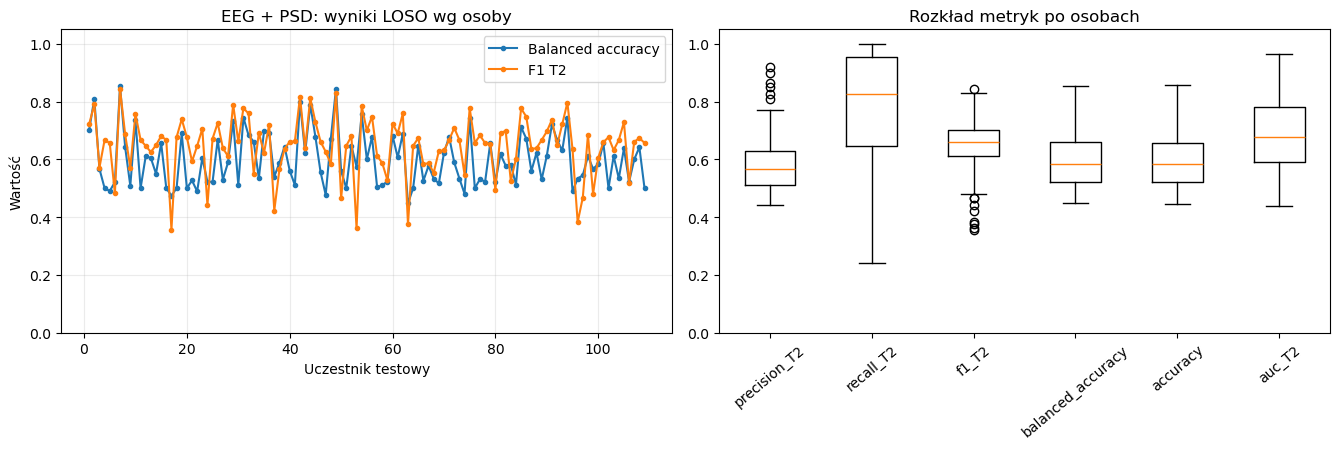

In [9]:
METRICS = ["precision_T2", "recall_T2", "f1_T2", "balanced_accuracy", "accuracy", "auc_T2"]
rows = []
for metric in METRICS:
    vals = results_df[metric].to_numpy(dtype=float)
    mean = float(vals.mean())
    std = float(vals.std(ddof=1)) if len(vals) > 1 else 0.0
    if len(vals) < 2 or np.isclose(std, 0.0):
        ci_low = ci_high = mean
    else:
        ci_low, ci_high = map(float, stats.t.interval(
            0.95, df=len(vals)-1, loc=mean, scale=stats.sem(vals)))
    rows.append({"metric": metric, "n_subjects": len(vals), "mean": mean,
                 "std": std, "CI95_lower": ci_low, "CI95_upper": ci_high})
summary_df = pd.DataFrame(rows)
summary_df.to_csv(OUTPUT_DIR / "podsumowanie_loso.csv", index=False)
print("Wyniki uczestników:")
display(results_df[["test_subject", *METRICS, "threshold_T2", "selected_epoch", "min_val_loss_epoch"]])
print("Średnia po osobach (nie po epokach) z 95% CI:")
display(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
axes[0].plot(results_df["test_subject"], results_df["balanced_accuracy"], "o-", ms=3,
             label="Balanced accuracy")
axes[0].plot(results_df["test_subject"], results_df["f1_T2"], "o-", ms=3,
             label="F1 T2")
axes[0].set(title="EEG + PSD: wyniki LOSO wg osoby", xlabel="Uczestnik testowy",
            ylabel="Wartość", ylim=(0, 1.05))
axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].boxplot([results_df[col] for col in METRICS], labels=METRICS)
axes[1].tick_params(axis="x", rotation=40)
axes[1].set(title="Rozkład metryk po osobach", ylim=(0, 1.05))
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / "wyniki_loso.png", dpi=150, bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

## 9. Macierz pomyłek i raport klasyfikacji (zagregowane predykcje LOSO)

Zagregowany raport per epoka (oprócz statystyki per osoba):
               precision    recall  f1-score   support

          T1       0.65      0.42      0.51      4950
          T2       0.57      0.77      0.66      4894

    accuracy                           0.60      9844
   macro avg       0.61      0.60      0.58      9844
weighted avg       0.61      0.60      0.58      9844



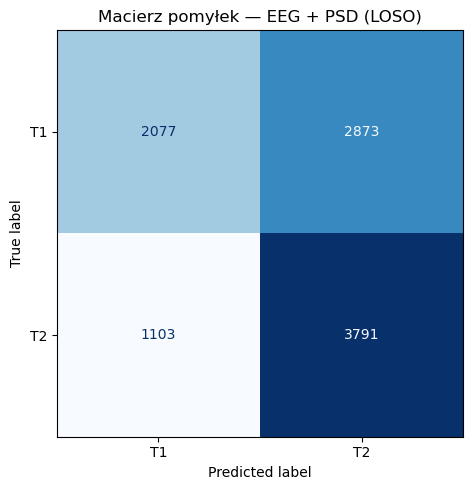

In [10]:
y_true_total = predictions_df["y_true"].to_numpy(dtype=np.int8)
y_pred_total = predictions_df["y_pred"].to_numpy(dtype=np.int8)
report_text = classification_report(y_true_total, y_pred_total, labels=[1, 2],
                                    target_names=["T1", "T2"], zero_division=0)
(OUTPUT_DIR / "raport_klasyfikacji.txt").write_text(report_text, encoding="utf-8")
print("Zagregowany raport per epoka (oprócz statystyki per osoba):\n", report_text)
cm = confusion_matrix(y_true_total, y_pred_total, labels=[1, 2])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["T1", "T2"]).plot(ax=ax,
    cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Macierz pomyłek — EEG + PSD (LOSO)")
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / "macierz_pomylek.png", dpi=160, bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

## 10. Krzywe treningu / walidacji wybranego folda

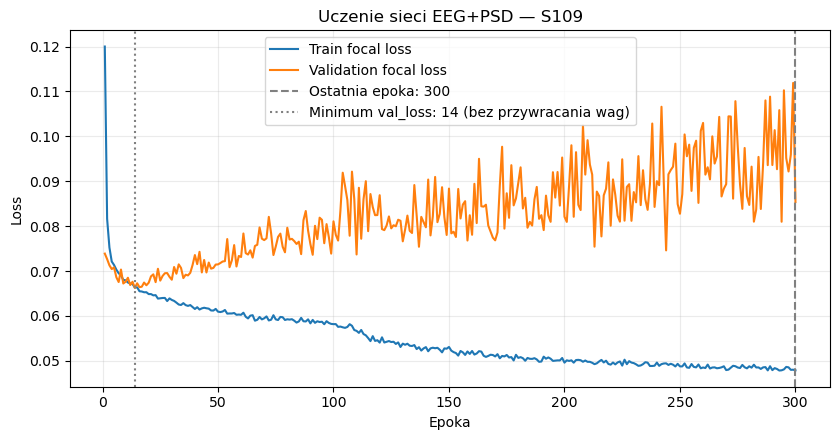

In [11]:
PLOT_SUBJECT = (int(results_df.iloc[-1]["test_subject"])
                if TEST_SUBJECT_TO_SHOW is None else int(TEST_SUBJECT_TO_SHOW))
if PLOT_SUBJECT not in results_df["test_subject"].values:
    raise ValueError("Wybrany testowy uczestnik nie należał do uruchomionych foldów.")
curve = history_df[(history_df["test_subject"] == PLOT_SUBJECT) &
                   (history_df["stage"] == "validation_fit")]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(curve["epoch"], curve["train_loss"], label="Train focal loss")
ax.plot(curve["epoch"], curve["val_loss"], label="Validation focal loss")
best = int(results_df.set_index("test_subject").loc[PLOT_SUBJECT, "selected_epoch"])
ax.axvline(best, ls="--", color="gray", label=f"Ostatnia epoka: {best}")
min_epoch = int(results_df.set_index("test_subject").loc[PLOT_SUBJECT, "min_val_loss_epoch"])
if min_epoch != best:
    ax.axvline(min_epoch, ls=":", color="gray", label=f"Minimum val_loss: {min_epoch} (bez przywracania wag)")
ax.set(xlabel="Epoka", ylabel="Loss", title=f"Uczenie sieci EEG+PSD — S{PLOT_SUBJECT:03d}")
ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / f"krzywa_uczenia_S{PLOT_SUBJECT:03d}.png", dpi=160,
                bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

## 11. Przykładowe predykcje i sprawdzenie odtwarzania zapisanego modelu

In [12]:
selected = (predictions_df[predictions_df["test_subject"] == PLOT_SUBJECT]
            .sort_values("test_epoch").reset_index(drop=True))
print("Predykcje osoby:", PLOT_SUBJECT, "| liczba epok:", len(selected))
for r in selected.head(N_SAMPLES).itertuples():
    print(f"Epoka {int(r.test_epoch):02d} | R{int(r.run):02d} | "
          f"prawda={CLASS_NAMES[int(r.y_true)]} | "
          f"pred={CLASS_NAMES[int(r.y_pred)]} | "
          f"P(T2)={float(r.probability_T2):.3f} | próg={float(r.threshold_T2):.2f}")

if SAVE_MODELS:
    prefix = MODEL_DIR / f"S{PLOT_SUBJECT:03d}"
    # Odczytuj wyłącznie zaufane checkpointy; weights_only ogranicza deserializację.
    checkpoint = torch.load(str(prefix) + ".pt", map_location="cpu", weights_only=True)
    loaded_model = build_master_eeg_psd_network(
        checkpoint["n_channels"], checkpoint["n_times"], checkpoint["n_freqs"])
    loaded_model.load_state_dict(checkpoint["model_state_dict"])
    loaded_model = loaded_model.to(DEVICE).eval()
    raw_scaler = joblib.load(str(prefix) + "_scaler_raw.joblib")  # tylko zaufane modele!
    psd_scaler = joblib.load(str(prefix) + "_scaler_psd.joblib")
    saved_meta = read_json(str(prefix) + "_metadata.json")
    assert saved_meta["dataset_id"] == manifest["dataset_id"]
    ids = selected["global_epoch_index"].to_numpy(dtype=np.int64)
    restored_probs = predict_probability_T2(loaded_model, ids, raw_scaler, psd_scaler)
    restored_labels = labels_from_probability(restored_probs, saved_meta["threshold_T2"])
    if not np.allclose(restored_probs, selected["probability_T2"].to_numpy(),
                       rtol=2e-5, atol=2e-6):
        raise AssertionError("Zapisany model nie odtwarza predykcji w CSV.")
    if not np.array_equal(restored_labels, selected["y_pred"].to_numpy()):
        raise AssertionError("Zapisany model nie odtwarza etykiet w CSV.")
    print("OK: model .pt i skalery .joblib odtwarzają predykcje dla osoby", PLOT_SUBJECT)
    del loaded_model, checkpoint
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

print("\nWyniki zapisano w:", OUTPUT_DIR)
print("Pliki: wyniki_per_subject.csv, predykcje_epok.csv, podzialy_uczestnikow.csv,")
print("       historia_uczenia.csv, podsumowanie_loso.csv, raport_klasyfikacji.txt")
if SAVE_MODELS:
    print("       modele/Sxxx.pt, modele/Sxxx_scaler_raw.joblib,")
    print("       modele/Sxxx_scaler_psd.joblib, modele/Sxxx_metadata.json")


Predykcje osoby: 109 | liczba epok: 90
Epoka 01 | R03 | prawda=lewa dłoń | pred=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 02 | R03 | prawda=prawa dłoń | pred=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 03 | R03 | prawda=lewa dłoń | pred=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 04 | R03 | prawda=prawa dłoń | pred=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 05 | R03 | prawda=prawa dłoń | pred=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 06 | R03 | prawda=lewa dłoń | pred=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 07 | R03 | prawda=lewa dłoń | pred=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 08 | R03 | prawda=prawa dłoń | pred=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 09 | R03 | prawda=lewa dłoń | pred=prawa dłoń | P(T2)=0.999 | próg=0.50
Epoka 10 | R03 | prawda=prawa dłoń | pred=prawa dłoń | P(T2)=1.000 | próg=0.50
OK: model .pt i skalery .joblib odtwarzają predykcje dla osoby 109

Wyniki zapisano w: /home/wsl/phd/01_przygotowanie_danych_EEGMMIDB/wyniki_modeli/EEG_PSD_DUAL_BRANCH/0a8da1db